# Crowdcast: counting people with CSRNet (ShanghaiTech Part B)

**Part B vs Part A:** Part B has 716 photos of Shanghai streets (400 train, 316 test), all 1024×768.
They are much sparser than Part A, so the published CSRNet error is far lower (MAE 10.6 vs 68.2).

**Setup:** the Part A v2 recipe ([02_counting_model_partA_v2.ipynb](02_counting_model_partA_v2.ipynb)),
with one change, the density maps:

| | Part A v2 | Part B |
|---|---|---|
| Density-map blob width | geometry-adaptive (0.3 × distance to 3 nearest heads) | **fixed, sigma = 15 px** |

In sparse scenes the "3 nearest heads" can be far away, so adaptive blobs would get unrealistically
wide. The CSRNet paper uses a fixed sigma of 15 for Part B for this reason.

Everything else is unchanged: VGG-16 front end (ImageNet), LR 3e-5 while frozen, then `block4` fine-tuned
at 1e-5, 15% validation split, up to 20 epochs, early stopping after 5 epochs without improvement,
LR halving after 2. The 316 test images are only used at the end.

> **Note on this run:** training ran for 13 epochs (2026-11-10, ~5 h on a laptop CPU) and was then
> **stopped by hand** early in epoch 14: validation MAE had not improved for 3 epochs and the learning rate was down to
> 1.25e-6, so further gains were expected to be small. The best weights (epoch 10) were saved during
> training. Section 8 therefore shows the per-epoch history read from the training log, and sections
> 9-10 test that saved best model.

**Goal:** given a crowd photo, predict how many people are in it.

**Approach:** CSRNet density estimation with transfer learning (Decisions #5 and #6):
- **Front end:** VGG-16 pretrained on ImageNet, up to `block4_conv3`.
- **Back end:** 6 dilated convolutions plus a 1×1 output conv, trained here.
- The model outputs a *density map*. Its sum is the predicted count.

**How we stop overfitting:**
1. **Validation set:** 10% of training images are held out and never trained on.
2. **Save the best epoch only:** keep the weights with the lowest validation MAE, not the last ones.
3. **Early stopping:** stop if validation MAE doesn't improve for 3 epochs.
4. **Augmentation:** random 256×256 crops plus left-right flips, so every epoch sees different patches.
5. **Careful transfer learning:** VGG-16 stays frozen at first, then is unfrozen with a 10× smaller learning rate.
6. **Lower the learning rate when stuck** (halve it after 2 epochs with no improvement), plus a small L2 weight penalty on the new layers.
7. **Proof:** count error on training images vs validation images is plotted after every epoch. If the two lines split apart, the model is memorising.

## 1. Setup

In [1]:
import os, time, json, warnings
warnings.filterwarnings("ignore", category=UserWarning, module="keras")   # harmless shuffle / optimizer-state notices
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow info logs
# oneDNN (TensorFlow's CPU speed-up library) made full-image counting ~60x slower on this
# machine (60s vs 1s per 704x1024 photo, measured 2026-11-08), so it's switched off.
# Must be set before TensorFlow is imported (restart the kernel if TF was already loaded).
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import numpy as np
import scipy.io as sio
from scipy.spatial import cKDTree
from PIL import Image
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model, regularizers
from IPython.display import display

print("TensorFlow", tf.__version__, "| NumPy", np.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU") or "none (training on CPU)")

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
PART_B = os.path.join(ROOT, "data", "shanghaitech", "ShanghaiTech", "part_B")
CACHE_DIR = os.path.join(ROOT, "data", "cache")
WEIGHTS_DIR = os.path.join(ROOT, "weights")
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(WEIGHTS_DIR, exist_ok=True)
BEST_WEIGHTS = os.path.join(WEIGHTS_DIR, "csrnet_partB_best.weights.h5")

TensorFlow 2.20.0 | NumPy 2.5.4
GPUs: none (training on CPU)


In [2]:
# ---- Settings ----
SEED = 42
VAL_FRACTION = 0.15      # share of training images held out for validation
CROP = 256               # training patch size (multiple of 8)
CROPS_PER_IMAGE = 4      # random patches per image per epoch
BATCH_SIZE = 8
EPOCHS = 20
FREEZE_EPOCHS = 3        # epochs with VGG-16 frozen before fine-tuning it
LR_HEAD = 3e-5           # learning rate while VGG-16 is frozen
LR_FINETUNE = 1e-5       # learning rate once VGG-16 is unfrozen
L2 = 1e-4                # weight penalty on the new (back-end) layers
EARLY_STOP_PATIENCE = 5  # epochs without val improvement before stopping
LR_PATIENCE = 2          # epochs without val improvement before halving the LR
DENSITY_SCALE = 100.0    # targets are multiplied by this so values aren't tiny
DOWNSAMPLE = 8           # CSRNet output is 1/8 of the input size
FINETUNE_BLOCKS = ("block4",)   # VGG-16 blocks unfrozen after FREEZE_EPOCHS

tf.keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

## 2. Load Part B

Each image has a `.mat` file with the (x, y) position of every head.
The official split is 400 train and 316 test images. We take 15% of train as validation.

In [3]:
def load_split(split):
    img_dir = os.path.join(PART_B, f"{split}_data", "images")
    gt_dir = os.path.join(PART_B, f"{split}_data", "ground-truth")
    names = sorted(os.listdir(img_dir), key=lambda n: int(n.split("_")[1].split(".")[0]))
    items = []
    for name in names:
        info = sio.loadmat(os.path.join(gt_dir, "GT_" + name.replace(".jpg", ".mat")))["image_info"][0, 0][0, 0]
        img = Image.open(os.path.join(img_dir, name))
        items.append({"name": name, "points": info[0].astype(np.float32),
                      "count": float(info[1][0, 0]), "gray": img.mode == "L",
                      "image": np.array(img.convert("RGB"))})
    return items

t0 = time.time()
train_all = load_split("train")
test = load_split("test")

perm = rng.permutation(len(train_all))
n_val = int(round(VAL_FRACTION * len(train_all)))
val = [train_all[i] for i in perm[:n_val]]
train = [train_all[i] for i in perm[n_val:]]
print(f"Loaded in {time.time()-t0:.1f}s -> train {len(train)}, val {len(val)}, test {len(test)}")

for nm, items in [("train", train), ("val", val), ("test", test)]:
    c = np.array([it["count"] for it in items])
    print(f"{nm:>5}: people per image min {c.min():.0f}, mean {c.mean():.0f}, max {c.max():.0f}"
          f" | grayscale images: {sum(it['gray'] for it in items)}")

Loaded in 18.6s -> train 340, val 60, test 316
train: people per image min 12, mean 123, max 576 | grayscale images: 0
  val: people per image min 23, mean 120, max 521 | grayscale images: 0
 test: people per image min 9, mean 124, max 539 | grayscale images: 0


## 3. Density maps (fixed Gaussian, sigma = 15)

Each head becomes a small Gaussian blob that sums to 1, so **sum of the map = number of people**.
Part B is sparse, so every blob gets the same width (sigma = 15 px), as in the CSRNet paper for Part B.

CSRNet outputs a map 8× smaller than the image, so each map is **sum-pooled** 8×8. That keeps the
total the same. Maps are cached in `data/cache/` so this runs once.

In [4]:
MEAN_RGB = np.array([124, 117, 104], dtype=np.uint8)   # ImageNet mean: padding with it becomes ~0 after preprocessing

def padded_size(h, w):
    # Round up to a multiple of 8, and at least one crop in size.
    up = lambda v: max(CROP, int(np.ceil(v / DOWNSAMPLE)) * DOWNSAMPLE)
    return up(h), up(w)

def gaussian_1d(center, sigma, size):
    # Gaussian over pixel indices that fall inside the image.
    r = int(np.ceil(3 * sigma))
    lo, hi = max(0, int(center) - r), min(size, int(center) + r + 1)
    idx = np.arange(lo, hi)
    return lo, hi, np.exp(-0.5 * ((idx - center) / sigma) ** 2)

SIGMA = 15.0

def density_map(points, h, w, sigma=SIGMA):
    dmap = np.zeros((h, w), dtype=np.float32)
    inside = (points[:, 0] >= 0) & (points[:, 0] < w) & (points[:, 1] >= 0) & (points[:, 1] < h)
    pts = points[inside]
    if len(pts) == 0:
        return dmap, 0
    sigmas = np.full(len(pts), sigma)
    for (x, y), s in zip(pts, sigmas):
        y0, y1, gy = gaussian_1d(y, s, h)
        x0, x1, gx = gaussian_1d(x, s, w)
        blob = np.outer(gy, gx)
        dmap[y0:y1, x0:x1] += blob / blob.sum()   # each person adds exactly 1
    return dmap, len(pts)

def sum_pool(dmap, hp, wp):
    padded = np.zeros((hp, wp), dtype=np.float32)
    padded[:dmap.shape[0], :dmap.shape[1]] = dmap
    return padded.reshape(hp // DOWNSAMPLE, DOWNSAMPLE, wp // DOWNSAMPLE, DOWNSAMPLE).sum(axis=(1, 3))

def pad_image(img, hp, wp):
    out = np.empty((hp, wp, 3), dtype=np.uint8)
    out[:] = MEAN_RGB
    out[:img.shape[0], :img.shape[1]] = img
    return out

cache_file = os.path.join(CACHE_DIR, "partB_density_fixed15_v1.npz")
everything = {f"train/{it['name']}": it for it in train_all} | {f"test/{it['name']}": it for it in test}

t0 = time.time()
if os.path.exists(cache_file):
    cached = np.load(cache_file)
    for key, it in everything.items():
        it["full_density"] = None
        it["density"] = cached[key]
    print(f"Loaded cached density maps in {time.time()-t0:.1f}s")
else:
    to_save, dropped = {}, 0
    for key, it in everything.items():
        h, w = it["image"].shape[:2]
        dmap, n_inside = density_map(it["points"], h, w)
        dropped += len(it["points"]) - n_inside
        it["full_density"] = dmap
        it["density"] = to_save[key] = sum_pool(dmap, *padded_size(h, w))
    np.savez_compressed(cache_file, **to_save)
    print(f"Built {len(to_save)} density maps in {time.time()-t0:.1f}s "
          f"({dropped} head points fell outside their image and were dropped)")

for it in everything.values():
    it["padded"] = pad_image(it["image"], *padded_size(*it["image"].shape[:2]))

# Check: map totals should match the labelled counts (tiny gaps = the dropped out-of-bounds points).
gaps = np.array([abs(it["density"].sum() - it["count"]) for it in everything.values()])
print(f"|map sum - labelled count|: mean {gaps.mean():.3f}, max {gaps.max():.3f} people")

Loaded cached density maps in 0.8s


|map sum - labelled count|: mean 0.000, max 0.000 people


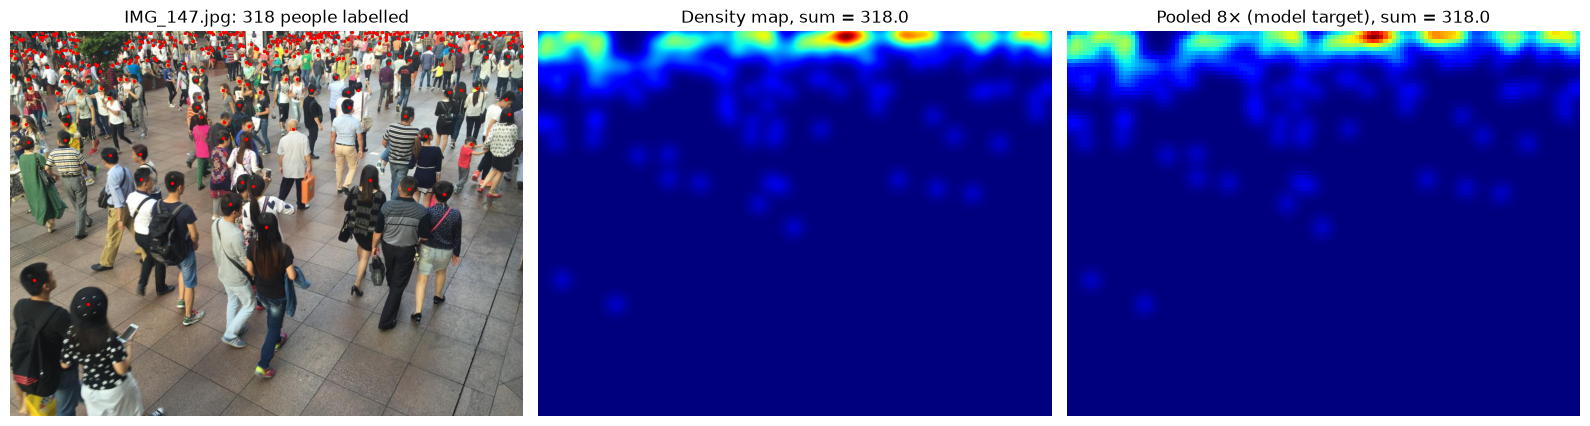

In [5]:
ex = train[0]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].imshow(ex["image"]); ax[0].set_title(f"{ex['name']}: {ex['count']:.0f} people labelled")
ax[0].scatter(ex["points"][:, 0], ex["points"][:, 1], s=2, c="red")
full = ex["full_density"] if ex["full_density"] is not None else density_map(ex["points"], *ex["image"].shape[:2])[0]
ax[1].imshow(full, cmap="jet"); ax[1].set_title(f"Density map, sum = {full.sum():.1f}")
ax[2].imshow(ex["density"], cmap="jet"); ax[2].set_title(f"Pooled 8× (model target), sum = {ex['density'].sum():.1f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 4. Baseline: always guess the average

Any model has to beat this. It predicts the mean training count for every image.

In [6]:
def mae_rmse(pred, true):
    err = np.asarray(pred) - np.asarray(true)
    return float(np.abs(err).mean()), float(np.sqrt((err ** 2).mean()))

mean_count = np.mean([it["count"] for it in train])
base_val = mae_rmse([mean_count] * len(val), [it["count"] for it in val])
base_test = mae_rmse([mean_count] * len(test), [it["count"] for it in test])
print(f"Mean-count baseline (always guess {mean_count:.0f}):")
print(f"  val  MAE {base_val[0]:.1f}, RMSE {base_val[1]:.1f}")
print(f"  test MAE {base_test[0]:.1f}, RMSE {base_test[1]:.1f}")

Mean-count baseline (always guess 123):
  val  MAE 74.9, RMSE 95.8
  test MAE 72.0, RMSE 95.1


## 5. Training data pipeline

Every epoch draws fresh random 256×256 crops (offsets on the 8-pixel grid so they line up with the
pooled target), flipped left-right half the time. Images go through VGG-16's own preprocessing.

In [7]:
preprocess = tf.keras.applications.vgg16.preprocess_input
OUT = CROP // DOWNSAMPLE

def random_crops():
    for i in rng.permutation(len(train) * CROPS_PER_IMAGE):
        it = train[i % len(train)]
        hp, wp = it["padded"].shape[:2]
        y = DOWNSAMPLE * rng.integers(0, (hp - CROP) // DOWNSAMPLE + 1)
        x = DOWNSAMPLE * rng.integers(0, (wp - CROP) // DOWNSAMPLE + 1)
        img = it["padded"][y:y + CROP, x:x + CROP]
        den = it["density"][y // DOWNSAMPLE:y // DOWNSAMPLE + OUT, x // DOWNSAMPLE:x // DOWNSAMPLE + OUT]
        if rng.random() < 0.5:
            img, den = img[:, ::-1], den[:, ::-1]
        yield preprocess(img.astype(np.float32)), (den * DENSITY_SCALE)[..., None].astype(np.float32)

train_ds = (tf.data.Dataset.from_generator(random_crops, output_signature=(
                tf.TensorSpec((CROP, CROP, 3), tf.float32), tf.TensorSpec((OUT, OUT, 1), tf.float32)))
            .batch(BATCH_SIZE).prefetch(2))
STEPS_PER_EPOCH = int(np.ceil(len(train) * CROPS_PER_IMAGE / BATCH_SIZE))

xb, yb = next(iter(train_ds))
print("batch images:", xb.shape, "| batch targets:", yb.shape, "| steps per epoch:", STEPS_PER_EPOCH)
print("people in this batch's crops:", np.round(yb.numpy().sum(axis=(1, 2, 3)) / DENSITY_SCALE, 1))

batch images: (8, 256, 256, 3) | batch targets: (8, 32, 32, 1) | steps per epoch: 170
people in this batch's crops: [ 0.8  3.8  1.   1.1  4.3 24.   2.   5.3]


## 6. Build CSRNet

- **Front end:** VGG-16 (ImageNet weights) truncated at `block4_conv3`: 10 conv layers, 3 poolings, so 1/8 resolution.
- **Back end:** 6 dilated 3×3 convs (dilation 2: wider view, no further shrinking) with 512, 512, 512, 256, 128, 64 channels, then a 1×1 conv down to one density channel.
- L2 penalty on the back end only. VGG-16 starts frozen.

In [8]:
def build_csrnet():
    vgg = tf.keras.applications.VGG16(include_top=False, weights="imagenet", input_shape=(None, None, 3))
    front = Model(vgg.input, vgg.get_layer("block4_conv3").output, name="vgg16_front")
    init = tf.keras.initializers.RandomNormal(stddev=0.01)
    x = front.output
    for i, ch in enumerate([512, 512, 512, 256, 128, 64]):
        x = layers.Conv2D(ch, 3, padding="same", dilation_rate=2, activation="relu",
                          kernel_initializer=init, kernel_regularizer=regularizers.l2(L2),
                          name=f"backend_conv{i+1}")(x)
    out = layers.Conv2D(1, 1, kernel_initializer=init, kernel_regularizer=regularizers.l2(L2), name="density")(x)
    return Model(front.input, out, name="csrnet"), front

model, front = build_csrnet()
front.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(LR_HEAD), loss="mse")

n_train = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
n_all = sum(int(np.prod(w.shape)) for w in model.weights)
print(f"Total parameters: {n_all:,} | trainable now (VGG-16 frozen): {n_train:,}")
model.summary(line_length=100, expand_nested=False)

Total parameters: 16,263,489 | trainable now (VGG-16 frozen): 8,628,225


Model: "csrnet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)                   │ (None, None, None, 3)           │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block1_conv1 (Conv2D)                      │ (None, None, None, 64)          │             1,792 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block1_conv2 (Conv2D)                      │ (None, None, None, 64)          │            36,928 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block1_pool (MaxPooling2D)                 │ (None, None, None, 64)          │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block2_conv1 (Conv2D)                      │ (None, None, None, 128)         │            73,856 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block2_conv2 (Conv2D)                      │ (None, None, None, 128)         │           147,584 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block2_pool (MaxPooling2D)                 │ (None, None, None, 128)         │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block3_conv1 (Conv2D)                      │ (None, None, None, 256)         │           295,168 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block3_conv2 (Conv2D)                      │ (None, None, None, 256)         │           590,080 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block3_conv3 (Conv2D)                      │ (None, None, None, 256)         │           590,080 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block3_pool (MaxPooling2D)                 │ (None, None, None, 256)         │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block4_conv1 (Conv2D)                      │ (None, None, None, 512)         │         1,180,160 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block4_conv2 (Conv2D)                      │ (None, None, None, 512)         │         2,359,808 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block4_conv3 (Conv2D)                      │ (None, None, None, 512)         │         2,359,808 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ backend_conv1 (Conv2D)                     │ (None, None, None, 512)         │         2,359,808 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ backend_conv2 (Conv2D)                     │ (None, None, None, 512)         │         2,359,808 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ backend_conv3 (Conv2D)                     │ (None, None, None, 512)         │         2,359,808 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ backend_conv4 (Conv2D)                     │ (None, None, None, 256)         │         1,179,904 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ backend_conv5 (Conv2D)                     │ (None, None, N

 Total params: 16,263,489 (62.04 MB)

 Trainable params: 8,628,225 (32.91 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

## 7. Counting on full images

Validation and test use whole images, not crops. Each image is padded to a multiple of 8 and the
predicted map is summed.

In [9]:
@tf.function(input_signature=[tf.TensorSpec([1, None, None, 3], tf.float32)], reduce_retracing=True)
def predict_map(x):
    return model(x, training=False)

def predict_count(it, return_map=False):
    dmap = predict_map(preprocess(it["padded"].astype(np.float32))[None])[0, ..., 0].numpy() / DENSITY_SCALE
    return (dmap.sum(), dmap) if return_map else dmap.sum()

def evaluate(items):
    preds = np.array([predict_count(it) for it in items])
    return mae_rmse(preds, [it["count"] for it in items]) + (preds,)

# Fixed subset of training images, measured the same way as validation, to compare the two.
train_check = [train[i] for i in rng.choice(len(train), size=len(val), replace=False)]

t0 = time.time()
mae0, rmse0, _ = evaluate(val)
print(f"Before training: val MAE {mae0:.1f}, RMSE {rmse0:.1f}  ({time.time()-t0:.1f}s for {len(val)} images)")

Before training: val MAE 120.7, RMSE 154.1  (191.9s for 60 images)


## 8. Training history (from the training log)

Training ran with the settings in section 1 and the loop from the Part A v2 notebook (per-epoch
validation, best-epoch checkpoint, LR halving, early stopping), logging one line per epoch to
`weights/csrnet_partB_train_log.txt`. It was stopped by hand after epoch 13 (see the note at the top).
This cell reads that log and plots train vs validation error.

08:59:56 Epoch 1/20 (LR 3e-05, VGG-16 frozen)
09:21:02   -> train MAE 68.0 | val MAE 60.6, RMSE 76.8 | 1266s | saved new best
09:21:02 Epoch 2/20 (LR 3e-05, VGG-16 frozen)
09:49:42   -> train MAE 21.7 | val MAE 17.3, RMSE 28.7 | 1720s | saved new best
09:49:42 Epoch 3/20 (LR 3e-05, VGG-16 frozen)
10:11:15   -> train MAE 22.9 | val MAE 23.9, RMSE 36.7 | 1293s | no improvement (1)
10:11:15 --- Unfroze VGG-16 block4 (14,528,001 trainable params), LR 1e-05 ---
10:11:15 Epoch 4/20 (LR 1e-05, VGG-16 block4 trainable)
10:28:43   -> train MAE 24.6 | val MAE 20.9, RMSE 35.9 | 1048s | no improvement (2)
10:28:43 Epoch 5/20 (LR 1e-05, VGG-16 block4 trainable)
10:54:01   -> train MAE 26.6 | val MAE 25.6, RMSE 37.9 | 1518s | no improvement (3)
10:54:01   -> halving learning rate to 5e-06
10:54:01 Epoch 6/20 (LR 5e-06, VGG-16 block4 trainable)
11:05:05   -> train MAE 18.3 | val MAE 15.1, RMSE 22.4 | 664s | saved new best
11:05:05 Epoch 7/20 (LR 5e-06, VGG-16 block4 trainable)
11:38:24   -> train MAE

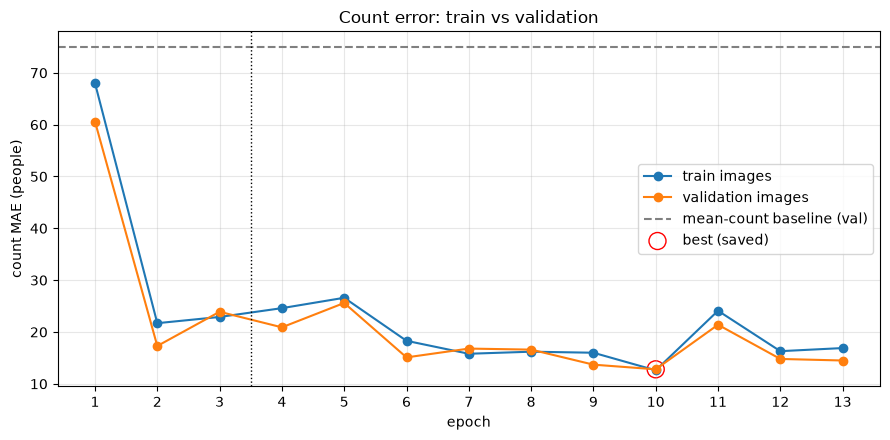

In [10]:
import re
LOG_FILE = os.path.join(WEIGHTS_DIR, "csrnet_partB_train_log.txt")
history = {"epoch": [], "train_mae": [], "val_mae": [], "val_rmse": [], "lr": []}
epoch, lr = None, None
with open(LOG_FILE, encoding="utf-8") as f:
    for line in f:
        print(line.rstrip())
        m = re.search(r"Epoch (\d+)/\d+ \(LR ([0-9.e-]+)", line)
        if m:
            epoch, lr = int(m.group(1)), float(m.group(2))
        m = re.search(r"train MAE ([0-9.]+) \| val MAE ([0-9.]+), RMSE ([0-9.]+)", line)
        if m:
            history["epoch"].append(epoch); history["lr"].append(lr)
            history["train_mae"].append(float(m.group(1)))
            history["val_mae"].append(float(m.group(2))); history["val_rmse"].append(float(m.group(3)))

best_i = int(np.argmin(history["val_mae"]))
best_mae, best_epoch = history["val_mae"][best_i], history["epoch"][best_i]
print(f"\n{len(history['epoch'])} epochs completed. Best val MAE {best_mae:.1f} at epoch {best_epoch}.")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(history["epoch"], history["train_mae"], "o-", label="train images")
ax.plot(history["epoch"], history["val_mae"], "o-", label="validation images")
ax.axhline(base_val[0], ls="--", c="gray", label="mean-count baseline (val)")
ax.axvline(FREEZE_EPOCHS + 0.5, ls=":", c="k", lw=1)
ax.scatter([best_epoch], [best_mae], s=150, facecolors="none", edgecolors="red", label="best (saved)")
ax.set(xlabel="epoch", ylabel="count MAE (people)", title="Count error: train vs validation", xticks=history["epoch"])
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

## 9. Test set results

Load the best-epoch weights (by validation MAE) and count all 316 test images. The test set was
not used for any decision during training.

In [11]:
model.load_weights(BEST_WEIGHTS)
t0 = time.time()
test_mae, test_rmse, test_preds = evaluate(test)
test_true = np.array([it["count"] for it in test])
print(f"Counted {len(test)} test images in {time.time()-t0:.0f}s\n")

rows = [("Mean-count baseline", *base_test),
        (f"CSRNet, ours (best of {len(history['epoch'])} epochs, epoch {best_epoch}; stopped by hand)", test_mae, test_rmse),
        ("CSRNet, published paper (Part B)", 10.6, 16.0)]
print(f"{'Method':<55}{'MAE':>8}{'RMSE':>9}")
for name, m, r in rows:
    print(f"{name:<55}{m:>8.1f}{r:>9.1f}")
print(f"\nImprovement over baseline: {100*(1-test_mae/base_test[0]):.0f}% lower MAE")

Counted 316 test images in 1323s

Method                                                      MAE     RMSE
Mean-count baseline                                        72.0     95.1
CSRNet, ours (best of 13 epochs, epoch 10; stopped by hand)    13.4     20.6
CSRNet, published paper (Part B)                           10.6     16.0

Improvement over baseline: 81% lower MAE


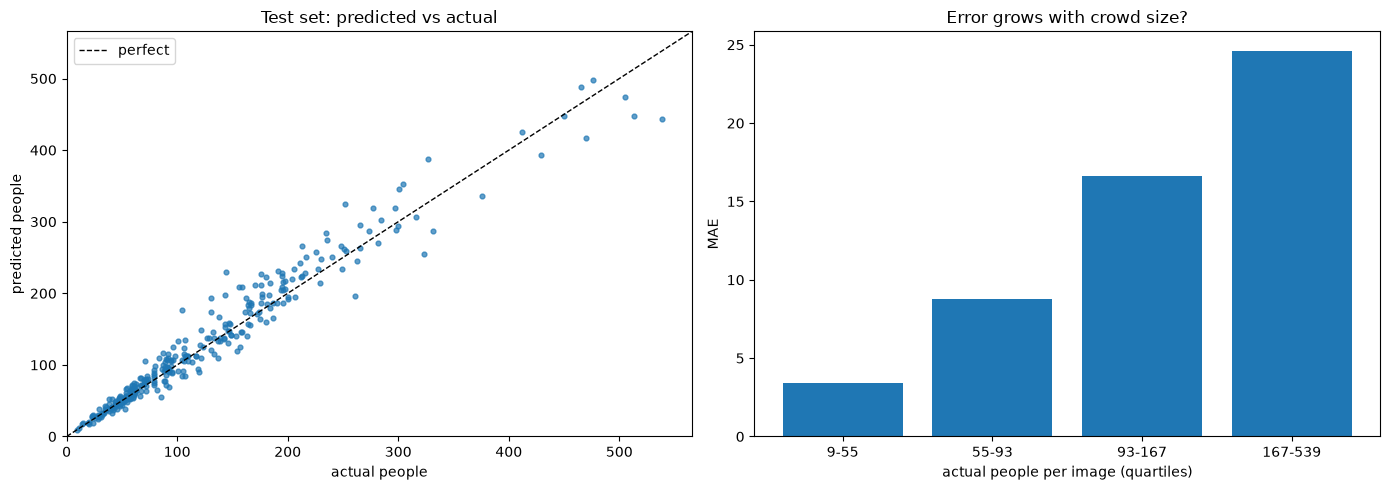

Average signed error: +4.6 people (negative = undercounts)


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
lim = max(test_true.max(), test_preds.max()) * 1.05
ax[0].scatter(test_true, test_preds, s=12, alpha=.7)
ax[0].plot([0, lim], [0, lim], "k--", lw=1, label="perfect")
ax[0].set(xlabel="actual people", ylabel="predicted people", title="Test set: predicted vs actual", xlim=(0, lim), ylim=(0, lim))
ax[0].legend()

bins = np.quantile(test_true, [0, .25, .5, .75, 1])
which = np.clip(np.digitize(test_true, bins[1:-1]), 0, 3)
labels = [f"{bins[i]:.0f}-{bins[i+1]:.0f}" for i in range(4)]
ax[1].bar(labels, [np.abs(test_preds - test_true)[which == i].mean() for i in range(4)])
ax[1].set(xlabel="actual people per image (quartiles)", ylabel="MAE", title="Error grows with crowd size?")
plt.tight_layout(); plt.show()

print(f"Average signed error: {np.mean(test_preds - test_true):+.1f} people (negative = undercounts)")

## 10. Sample predictions

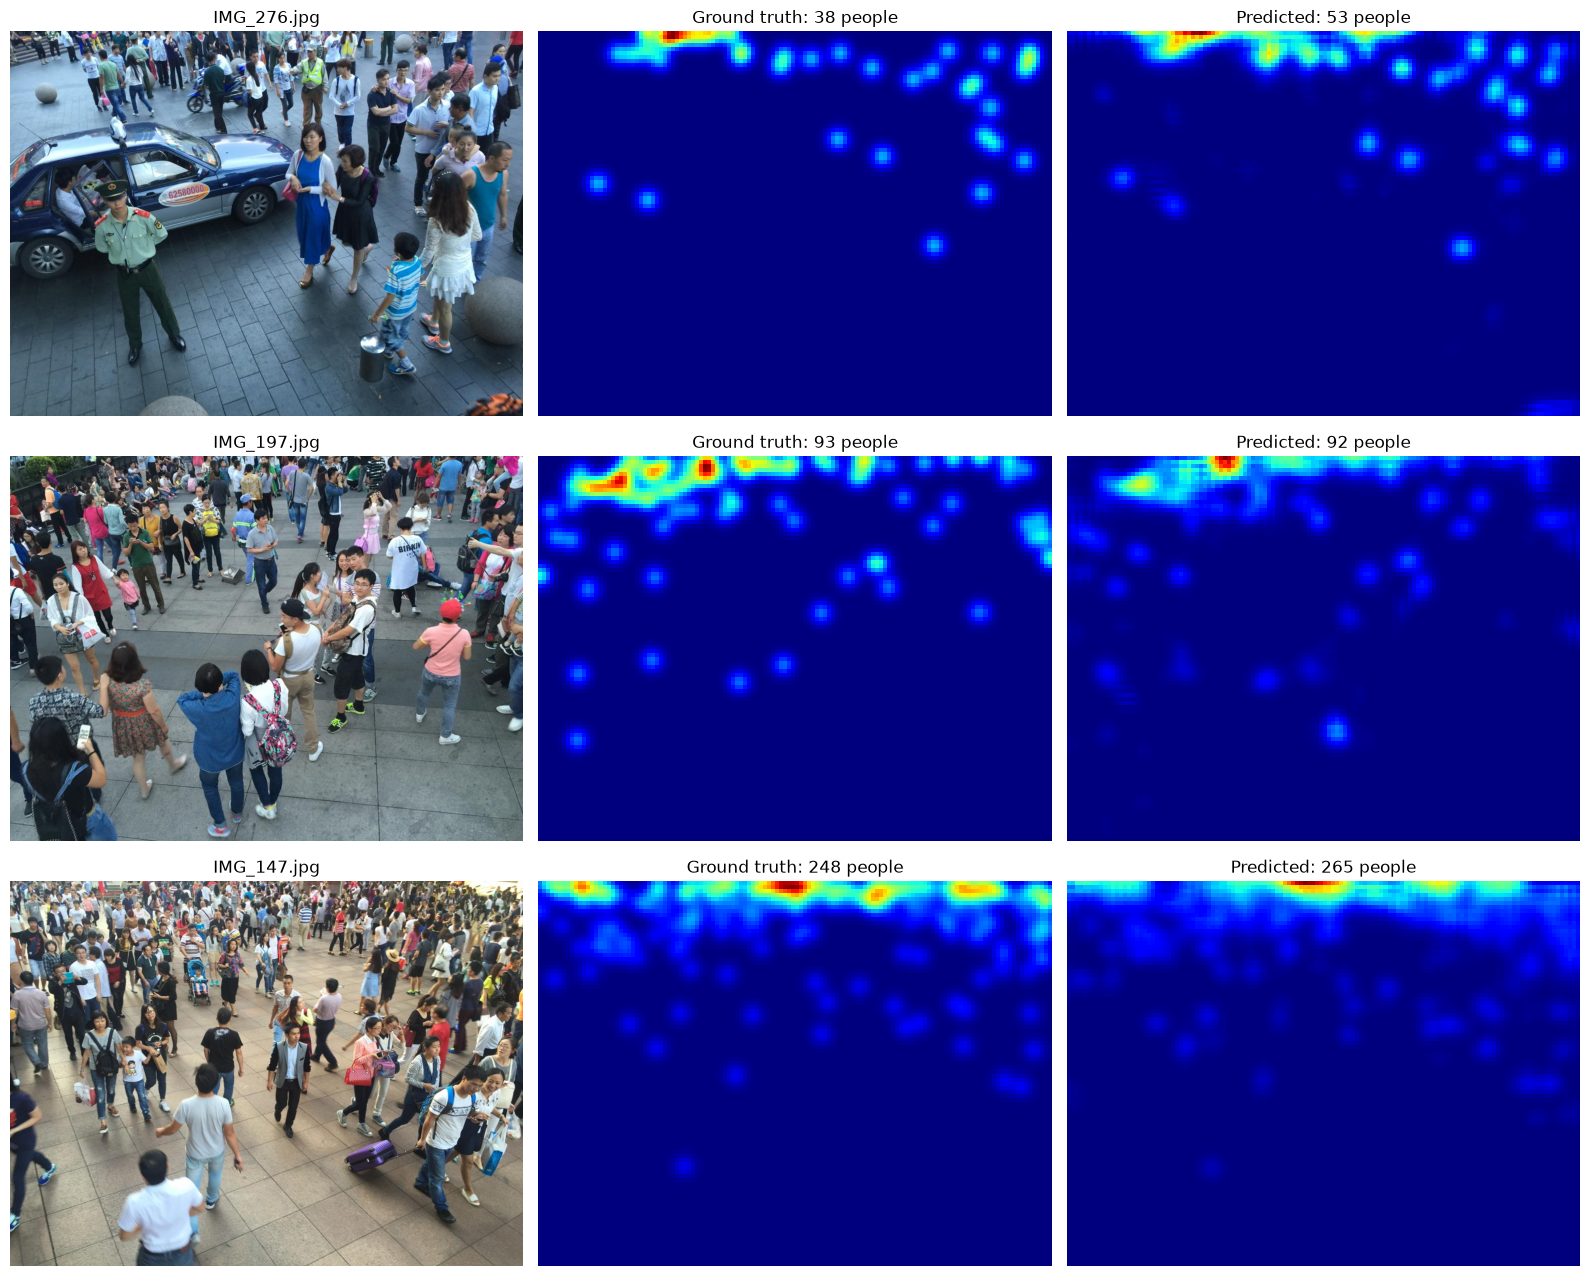

In [13]:
order = np.argsort(test_true)
picks = [order[len(order) // 10], order[len(order) // 2], order[-len(order) // 10]]   # sparse, medium, dense
fig, ax = plt.subplots(3, 3, figsize=(16, 13))
for row, i in enumerate(picks):
    it = test[i]
    pred, pmap = predict_count(it, return_map=True)
    h, w = it["image"].shape[:2]
    ax[row, 0].imshow(it["image"]); ax[row, 0].set_title(it["name"])
    ax[row, 1].imshow(it["density"][:h // 8, :w // 8], cmap="jet"); ax[row, 1].set_title(f"Ground truth: {it['count']:.0f} people")
    ax[row, 2].imshow(np.maximum(pmap[:h // 8, :w // 8], 0), cmap="jet"); ax[row, 2].set_title(f"Predicted: {pred:.0f} people")
    for a in ax[row]: a.axis("off")
plt.tight_layout(); plt.show()